In [2]:
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# --- 1. Load Data & Snappshot Data ---
df = pd.read_csv("../data/processed/online_retail_cleaned.csv")
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(f"Data loaded: {df.shape}")
print(f"Date range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)


Data loaded: (776577, 9)
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [3]:
# --- 2. RFM Calculation ---
rfm = df.groupby('Customer ID').agg({
    'InvoiceDate' : lambda x: (snapshot_date - x.max()).days,
    'Invoice': 'nunique',
    'TotalPrice': 'sum'
}).reset_index()

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

print(rfm.head())

   CustomerID  Recency  Frequency  Monetary
0       12346      326          3  77352.96
1       12347        2          8   4921.53
2       12348       75          5   1658.40
3       12349       19          3   3678.69
4       12350      310          1    294.40


In [4]:
# --- 3. RFM scoring & Segmentation ---
rfm['R_Score'] = pd.qcut(rfm['Recency'], 4, labels=[4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method = 'first'), 4, labels = [1, 2, 3, 4]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 4, labels = [1, 2, 3, 4]).astype(int)

rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

# Simple segmentation logic
def segment_customer(row):
    if row['R_Score'] >= 3 and row['F_Score'] >= 3 and row['M_Score'] >=3:
        return 'VIP'
    elif row['R_Score'] >= 3 and row['F_Score'] >= 2:
        return 'Loyal'
    elif row['R_Score'] <= 2 and row['F_Score'] >=2:
        return 'At Risk'
    else:
        return 'Lost'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)
print(rfm['Segment'].value_counts())

Segment
VIP        1804
At Risk    1795
Lost       1463
Loyal       790
Name: count, dtype: int64


In [5]:
# --- 4. Cohort Analysis ---
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')
df['CohortMonth'] = df.groupby('Customer ID')['InvoiceDate'].transform('min').dt.to_period('M')

def get_date_int(df, column):
    year = df[column].dt.year
    month = df[column].dt.month
    return year, month

invoice_year, invoice_month = get_date_int(df, 'InvoiceMonth')
cohort_year, cohort_month = get_date_int(df, 'CohortMonth')

years_diff = invoice_year - cohort_year
months_diff = invoice_month - cohort_month

df['CohortIndex'] = years_diff * 12 + months_diff

cohort_data = df.groupby(['CohortMonth', 'CohortIndex'])['Customer ID'].nunique().reset_index()
cohort_pivot = cohort_data.pivot(index='CohortMonth', columns = 'CohortIndex', values = 'Customer ID')

#Retention Rate 
cohort_size = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_size, axis = 0)
print(retention_matrix.head())

CohortIndex   0         1         2         3         4         5         6   \
CohortMonth                                                                    
2009-12      1.0  0.350158  0.333333  0.424816  0.378549  0.359621  0.376446   
2010-01      1.0  0.214674  0.320652  0.315217  0.271739  0.309783  0.269022   
2010-02      1.0  0.234667  0.226667  0.293333  0.245333  0.197333  0.192000   
2010-03      1.0  0.190476  0.231293  0.242630  0.231293  0.204082  0.247166   
2010-04      1.0  0.190476  0.190476  0.159864  0.183673  0.221088  0.275510   

CohortIndex        7         8         9   ...        15        16        17  \
CohortMonth                                ...                                 
2009-12      0.343849  0.337539  0.361725  ...  0.302839  0.262881  0.302839   
2010-01      0.233696  0.285326  0.326087  ...  0.152174  0.244565  0.203804   
2010-02      0.288000  0.256000  0.277333  ...  0.200000  0.160000  0.162667   
2010-03      0.306122  0.276644  0.1088

In [6]:
# --- 5. Save outputs ---
os.makedirs("../data/processed", exist_ok = True)
rfm.to_csv("../data/processed/rfm_segments.csv", index= False)
retention_matrix.to_csv("../data/processed/cohort_retention.csv")
print("Saved RFM and Cohort files to data/processed/")

Saved RFM and Cohort files to data/processed/


C:\Users\Toranj\AppData\Local\Temp\ipykernel_4308\1041037374.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm, x='Segment', order=rfm['Segment'].value_counts().index, palette='viridis')


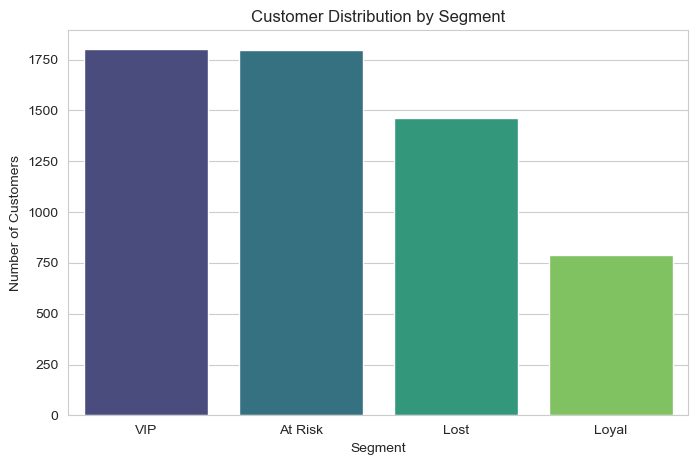

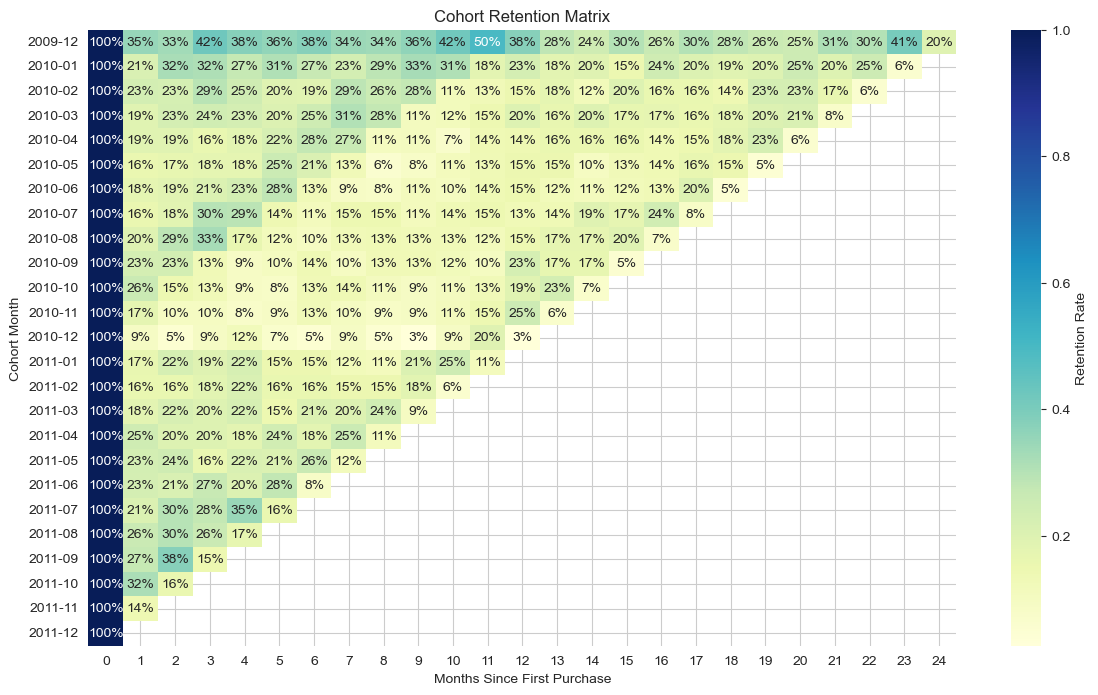

In [7]:
# --- 6. Visualizations ---
# Plot Distribution of Segments
plt.figure(figsize=(8, 5))
sns.countplot(data=rfm, x='Segment', order=rfm['Segment'].value_counts().index, palette='viridis')
plt.title('Customer Distribution by Segment')
plt.ylabel('Number of Customers')
plt.show()

# Plot Cohort Retention Heatmap
plt.figure(figsize=(14, 8))
sns.heatmap(retention_matrix, annot=True, fmt='.0%', cmap='YlGnBu', cbar_kws={'label': 'Retention Rate'})
plt.title('Cohort Retention Matrix')
plt.ylabel('Cohort Month')
plt.xlabel('Months Since First Purchase')
plt.show()

Top 10 Countries with the Most VIP Customers:
Country
United Kingdom    1644
Germany             39
France              37
Belgium             12
Spain                9
Switzerland          7
Denmark              7
Italy                6
Finland              5
Portugal             5
Name: count, dtype: int64


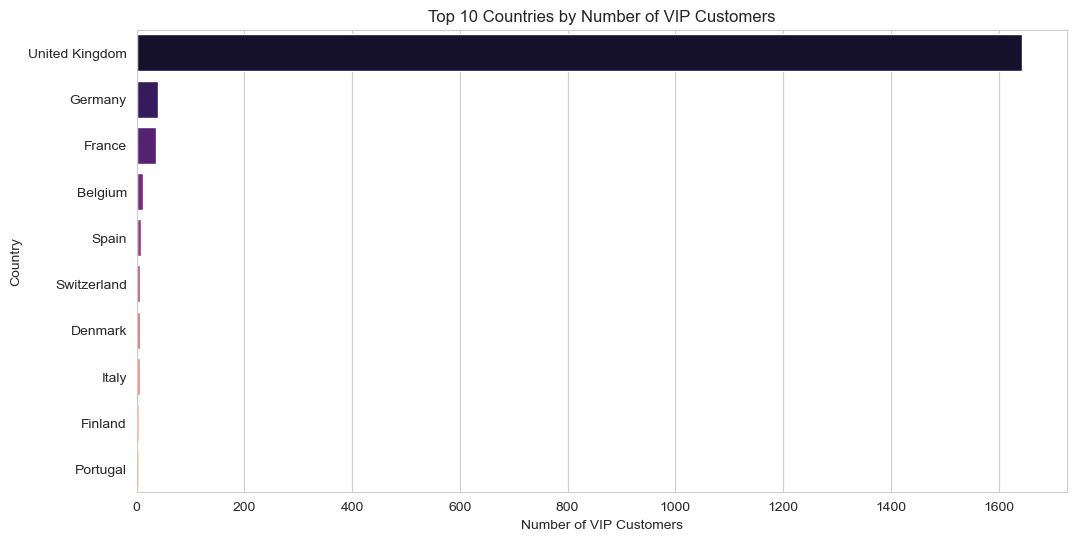

In [8]:
# 1. Merge the RFM table with the country data
# We need to get the country for each customer from the original df
customer_countries = df.groupby('Customer ID')['Country'].first().reset_index()
rfm_with_country = rfm.merge(customer_countries, left_on='CustomerID', right_on='Customer ID', how='left')

# 2. Analyze VIP customers by Country
vip_by_country = rfm_with_country[rfm_with_country['Segment'] == 'VIP']['Country'].value_counts().head(10)

print("Top 10 Countries with the Most VIP Customers:")
print(vip_by_country)

# 3. Visualize it
plt.figure(figsize=(12, 6))
sns.barplot(x=vip_by_country.values, y=vip_by_country.index, palette='magma', hue=vip_by_country.index, legend=False)
plt.title('Top 10 Countries by Number of VIP Customers')
plt.xlabel('Number of VIP Customers')
plt.ylabel('Country')
plt.show()